# Section 10. Constant Volatility BS Benchmark and Issue Margin

이 노트북은 실제 발행사의 full pricing engine을 복제하려는 섹션이 아니다. 목적은 **상수변동성 Black-Scholes benchmark에서 할 수 있는 분석을 끝까지 수행한 뒤, 그 결과가 실제 발행상품과 왜 어긋날 수 있는지 한계까지 명시하는 것**이다.

핵심 질문은 다음과 같다.

1. 현재 상품 조건을 상수변동성 BS 세계에서 평가하면 ELS fair value는 얼마인가?
2. 판매가격 100억원과 fair value의 차이로 정의한 발행마진은 양수인가?
3. 변동성 `sigma`와 배당수익률 `q`를 바꾸면 fair value와 발행마진은 얼마나 달라지는가?
4. 판매수수료와 동적헤지 30bp 비용을 반영해도 발행사 terminal balance가 버틸 수 있는가?
5. 이 benchmark가 실제 미래에셋 발행가격을 설명하지 못한다면, 그 한계는 무엇인가?

주의: 이 노트북은 결과 확인용 섹션이므로 `output` 파일을 새로 저장하지 않는다. 모든 결과는 노트북 내부 표와 그래프로만 확인한다.

## 10-0. 분석 구조

가격과 운용성과를 섞지 않기 위해 두 종류의 path를 구분한다.

| 구분 | 목적 | drift | 사용 위치 |
|---|---|---:|---|
| Risk-neutral path | ELS fair value 산정 | `r - q` | Section 10 pricing |
| 기존 project path | 발행사 운용성과 분석 | 기존 Section 2 설정 | Section 7~9 terminal balance |

기본 pricing은 `q = 0`인 상수변동성 Black-Scholes benchmark로 시작한다.

```text
ELS fair value = mean(exp(-r * settlement_year_i) * investor_payoff_i)
```

그 다음 같은 상수변동성 틀 안에서 `sigma`와 `q` 민감도를 확인한다.

```text
dS / S = (r - q) dt + sigma dW
```

따라서 이 섹션의 결론은 “실제 발행가를 맞췄다”가 아니라, **단순 BS benchmark가 어떤 가격을 주고, 그 가격이 어떤 입력값에 민감한지**를 보여주는 데 있다.

In [1]:
# ============================================================
# 10-1. Import and Display Setting
# ============================================================

# 수치 계산, 표 정리, 그래프 작성을 위한 기본 패키지다.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 파일 경로와 노트북 출력 표시를 위한 도구다.
from pathlib import Path
from IPython.display import display, Markdown

# 노트북을 읽을 때 불필요한 경고가 흐름을 방해하지 않도록 숨긴다.
import warnings
warnings.filterwarnings("ignore")

# 금액 표시는 억원 단위 컬럼을 읽기 쉽게 하기 위한 설정이다.
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

In [2]:
# ============================================================
# 10-2. Project Path and Existing Result Loading
# ============================================================

# 이 노트북은 ELS hege 5.19 폴더 안에서 실행하는 것을 기준으로 한다.
# 다른 위치에서 실행해도 상위 폴더를 타고 올라가며 프로젝트 폴더를 찾는다.
PROJECT_NAME = "ELS hege 5.19"
current = Path.cwd().resolve()

if current.name == PROJECT_NAME:
    PROJECT_DIR = current
else:
    PROJECT_DIR = None
    for parent in [current, *current.parents]:
        candidate = parent / PROJECT_NAME
        if candidate.exists():
            PROJECT_DIR = candidate.resolve()
            break
    if PROJECT_DIR is None:
        raise FileNotFoundError(f"Cannot find project folder: {PROJECT_NAME}")

OUTPUT_DIR = PROJECT_DIR / "output"

# 기존 섹션이 만든 결과는 읽기만 한다.
# 이 노트북에서는 np.save, to_csv, savefig를 사용하지 않는다.
market_params = pd.read_csv(OUTPUT_DIR / "market_params.csv").iloc[0].to_dict()
autocall_schedule = pd.read_csv(OUTPUT_DIR / "autocall_schedule.csv")

sim_dates = pd.read_csv(OUTPUT_DIR / "sim_dates.csv")
sim_dates["Date"] = pd.to_datetime(sim_dates["Date"])
sim_dates = pd.DatetimeIndex(sim_dates["Date"])

payoff_df_real = pd.read_csv(OUTPUT_DIR / "els_payoff_result.csv")
experiment_grid = pd.read_csv(OUTPUT_DIR / "experiment_grid.csv").reset_index()
experiment_grid = experiment_grid.rename(columns={"index": "experiment_id"})

static_pnl_terminal_matrix = np.load(OUTPUT_DIR / "static_pnl_terminal_matrix.npy")
existing_paths = np.load(OUTPUT_DIR / "mc_paths.npy")
S_GRID = np.load(OUTPUT_DIR / "fdm_S_GRID.npy")
delta_ki_grid = np.load(OUTPUT_DIR / "fdm_delta_ki_grid.npy")
delta_noki_grid = np.load(OUTPUT_DIR / "fdm_delta_noki_grid.npy")

load_check = pd.DataFrame({
    "item": [
        "market_params", "autocall_schedule", "sim_dates",
        "payoff_df_real", "experiment_grid", "existing_paths"
    ],
    "shape_or_length": [
        "1 row", autocall_schedule.shape, len(sim_dates),
        payoff_df_real.shape, experiment_grid.shape, existing_paths.shape
    ],
})

display(load_check)

,item,shape_or_length
0,market_params,1 row
1,autocall_schedule,"(6, 6)"
2,sim_dates,780
3,payoff_df_real,"(10000, 12)"
4,experiment_grid,"(33, 9)"
5,existing_paths,"(10000, 780)"


In [3]:
# ============================================================
# 10-3. Product and Pricing Assumptions
# ============================================================

# 기존 프로젝트의 상품 조건을 그대로 둔다.
NOTIONAL = 10_000_000_000       # 투자자 납입금 / 판매가격: 100억원
SALE_PRICE = NOTIONAL           # 공모 ELS는 보통 액면 100 기준으로 판매된다고 가정한다.
S0 = float(market_params["S0"])
SIGMA = float(market_params["SIGMA"])
RISK_FREE_RATE = float(market_params["RISK_FREE_RATE"])
TRADING_DAYS = int(market_params["TRADING_DAYS"])

ANNUAL_COUPON = 0.097           # 투자자에게 제시된 연 9.7% 쿠폰
MATURITY_YEARS = 3.0
KNOCK_IN_BARRIER = 0.35
PRINCIPAL_DAILY_RATE = 0.03 / 365
DYNAMIC_TC_BPS = 30             # 사용자 조건: 동적헤지 거래비용/패널티는 30bp로 고정한다.

assumption_table = pd.DataFrame([
    ["Sale price", SALE_PRICE / 1e8, "억원", "투자자 납입금"],
    ["Annual coupon", ANNUAL_COUPON * 100, "%", "투자자에게 제시된 쿠폰"],
    ["BS volatility", SIGMA * 100, "%", "기존 프로젝트 3년 historical volatility"],
    ["Risk-free rate", RISK_FREE_RATE * 100, "%", "risk-neutral pricing drift and discount"],
    ["Knock-in barrier", KNOCK_IN_BARRIER * 100, "% of S0", "기존 프로젝트 조건"],
    ["Dynamic hedge TC", DYNAMIC_TC_BPS, "bp", "Section 10에서 고정"],
], columns=["assumption", "value", "unit", "comment"])

display(assumption_table)

,assumption,value,unit,comment
0,Sale price,100.0000,억원,투자자 납입금
1,Annual coupon,9.7000,%,투자자에게 제시된 쿠폰
2,BS volatility,27.2042,%,기존 프로젝트 3년 historical volatility
3,Risk-free rate,3.0000,%,risk-neutral pricing drift and discount
4,Knock-in barrier,35.0000,% of S0,기존 프로젝트 조건
5,Dynamic hedge TC,30.0000,bp,Section 10에서 고정


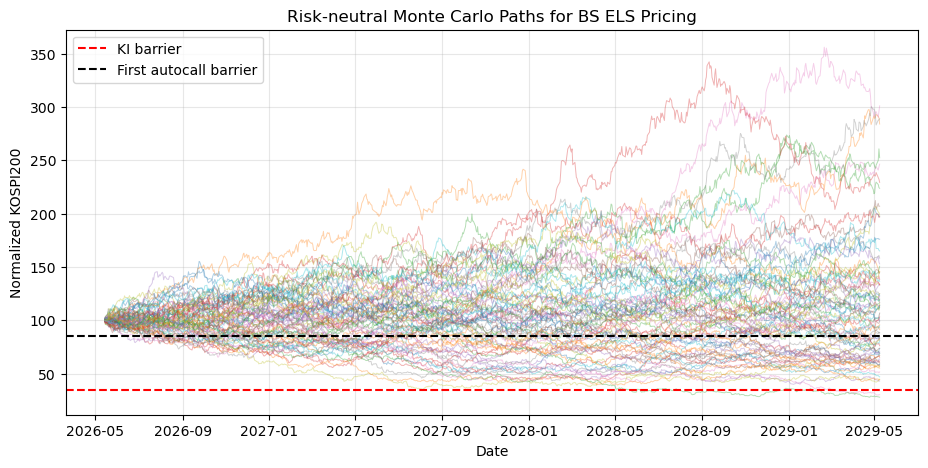

,final_price
count,"20,000.0000"
mean,110.1103
std,54.7710
min,16.4591
25%,71.5975
50%,98.7585
75%,135.1430
max,580.9815


In [4]:
# ============================================================
# 10-4. Risk-neutral Monte Carlo Path Generation
# ============================================================

# ELS fair value는 risk-neutral measure에서 계산해야 한다.
# 따라서 drift는 historical mean return이 아니라 risk-free rate r을 사용한다.
N_PRICING_PATHS = 20_000
N_STEPS = len(sim_dates) - 1
DT = MATURITY_YEARS / N_STEPS
SEED = 20260521

rng = np.random.default_rng(SEED)
z = rng.standard_normal((N_PRICING_PATHS, N_STEPS))

rn_log_increment = (
    (RISK_FREE_RATE - 0.5 * SIGMA ** 2) * DT
    + SIGMA * np.sqrt(DT) * z
)

rn_paths = np.empty((N_PRICING_PATHS, N_STEPS + 1), dtype=float)
rn_paths[:, 0] = S0
rn_paths[:, 1:] = S0 * np.exp(np.cumsum(rn_log_increment, axis=1))

# 샘플 path를 그려서 risk-neutral pricing path가 정상적으로 생성되었는지 확인한다.
plt.figure(figsize=(11, 5))
for i in range(80):
    plt.plot(sim_dates, rn_paths[i], linewidth=0.7, alpha=0.35)
plt.axhline(S0 * KNOCK_IN_BARRIER, linestyle="--", color="red", label="KI barrier")
plt.axhline(S0 * autocall_schedule.iloc[0]["barrier"], linestyle="--", color="black", label="First autocall barrier")
plt.title("Risk-neutral Monte Carlo Paths for BS ELS Pricing")
plt.xlabel("Date")
plt.ylabel("Normalized KOSPI200")
plt.legend()
plt.show()

display(pd.Series(rn_paths[:, -1], name="final_price").describe().to_frame())

In [5]:
# ============================================================
# 10-5. ELS Payoff Function
# ============================================================

# Section 3의 payoff 로직을 이 노트북 안에 다시 적는다.
# 이유는 Section 10만 단독으로 열어도 pricing 계산 흐름을 따라갈 수 있게 하기 위해서다.
def calculate_els_payoff(
    paths,
    autocall_schedule,
    notional,
    S0,
    annual_coupon,
    knock_in_barrier,
    maturity_years,
):
    '''
    Step-down knock-in ELS의 path별 투자자 payoff를 계산한다.

    투자자 관점:
    - investor_payoff는 투자자가 받는 금액이다.

    발행사 관점:
    - 같은 금액은 issuer_cash_outflow, 즉 발행사가 지급해야 하는 부채 현금흐름이다.
    '''

    n_paths = paths.shape[0]
    payoff = np.zeros(n_paths)
    payoff_type = np.array([""] * n_paths, dtype=object)

    autocall_occurred = np.zeros(n_paths, dtype=bool)
    autocall_no = np.zeros(n_paths, dtype=int)
    settlement_index = np.full(n_paths, paths.shape[1] - 1, dtype=int)
    elapsed_years = np.full(n_paths, maturity_years, dtype=float)

    # 조기상환 평가일마다 아직 상환되지 않은 path만 barrier 충족 여부를 확인한다.
    for _, row in autocall_schedule.iterrows():
        obs_no = int(row["autocall_no"])
        obs_idx = int(row["time_index"])
        barrier_level = float(row["barrier"]) * S0
        year_frac = float(row["year_fraction"])

        not_yet_called = ~autocall_occurred
        hit = paths[:, obs_idx] >= barrier_level
        newly_called = not_yet_called & hit

        payoff[newly_called] = notional * (1 + annual_coupon * year_frac)
        payoff_type[newly_called] = f"autocall_{obs_no}"
        autocall_occurred[newly_called] = True
        autocall_no[newly_called] = obs_no
        settlement_index[newly_called] = obs_idx
        elapsed_years[newly_called] = year_frac

    # 조기상환되지 않은 path는 만기 payoff를 계산한다.
    no_autocall = ~autocall_occurred
    final_price = paths[:, -1]
    min_price = paths.min(axis=1)

    ki_level = S0 * knock_in_barrier
    knock_in_occurred = min_price <= ki_level

    # 낙인이 없으면 만기에도 원금 + 전체 쿠폰을 지급한다.
    no_autocall_no_ki = no_autocall & (~knock_in_occurred)
    payoff[no_autocall_no_ki] = notional * (1 + annual_coupon * maturity_years)
    payoff_type[no_autocall_no_ki] = "maturity_no_knock_in"

    # 낙인이 있으면 final performance에 연동된다.
    no_autocall_ki = no_autocall & knock_in_occurred
    payoff[no_autocall_ki] = notional * (final_price[no_autocall_ki] / S0)
    payoff_type[no_autocall_ki] = "maturity_knock_in_loss"

    return pd.DataFrame({
        "path_id": np.arange(n_paths),
        "autocall_occurred": autocall_occurred,
        "autocall_no": autocall_no,
        "settlement_index": settlement_index,
        "elapsed_years": elapsed_years,
        "knock_in_occurred": knock_in_occurred,
        "final_price": final_price,
        "min_price": min_price,
        "payoff_type": payoff_type,
        "investor_payoff": payoff,
        "issuer_cash_outflow": payoff,
        "investor_return_rate": payoff / notional - 1,
    })

,metric,amount_krw,amount_100m,ratio_to_notional
0,Sale price,"10,000,000,000.0000",100.0000,1.0000
1,BS fair value,"10,398,117,641.8507",103.9812,1.0398
2,Monte Carlo standard error,"6,496,426.6998",0.0650,0.0006
3,Gross issue margin,"-398,117,641.8507",-3.9812,-0.0398


,payoff_type,probability,mean_payoff_100m,mean_discounted_payoff_100m
0,autocall_1,0.8024,104.8500,103.2890
1,autocall_2,0.0604,109.7000,106.4579
2,autocall_3,0.0279,114.5500,109.5095
3,autocall_4,0.0205,119.4000,112.4467
4,autocall_5,0.0161,124.2500,115.2721
5,autocall_6,0.0123,129.1000,117.9885
6,maturity_knock_in_loss,0.0132,35.7221,32.6476
7,maturity_no_knock_in,0.0473,129.1000,117.9885


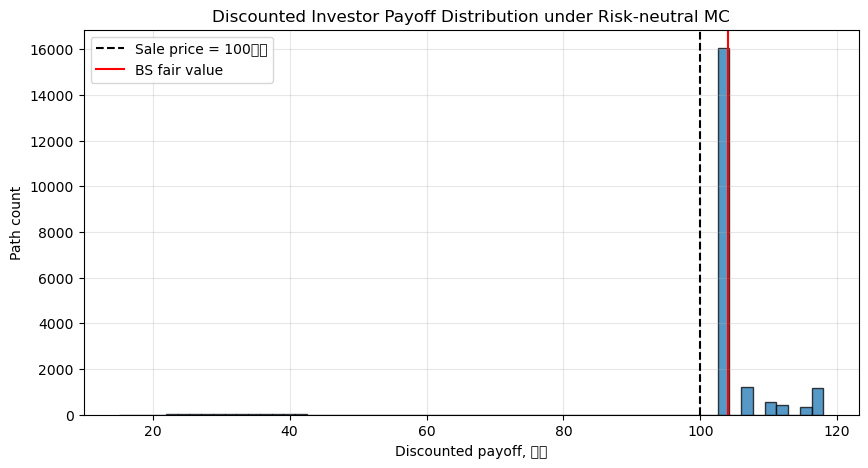

In [6]:
# ============================================================
# 10-6. Black-Scholes ELS Fair Value
# ============================================================

# Risk-neutral path에 투자자 payoff 로직을 적용한다.
rn_payoff_df = calculate_els_payoff(
    paths=rn_paths,
    autocall_schedule=autocall_schedule,
    notional=NOTIONAL,
    S0=S0,
    annual_coupon=ANNUAL_COUPON,
    knock_in_barrier=KNOCK_IN_BARRIER,
    maturity_years=MATURITY_YEARS,
)

# 각 path의 지급 시점이 다르므로 path별 settlement year로 할인한다.
rn_payoff_df["discount_factor"] = np.exp(-RISK_FREE_RATE * rn_payoff_df["elapsed_years"])
rn_payoff_df["discounted_payoff"] = (
    rn_payoff_df["investor_payoff"] * rn_payoff_df["discount_factor"]
)

ELS_FAIR_VALUE = rn_payoff_df["discounted_payoff"].mean()
FAIR_VALUE_SE = rn_payoff_df["discounted_payoff"].std(ddof=1) / np.sqrt(N_PRICING_PATHS)
GROSS_ISSUE_MARGIN = SALE_PRICE - ELS_FAIR_VALUE

pricing_summary = pd.DataFrame([
    ["Sale price", SALE_PRICE, SALE_PRICE / 1e8, SALE_PRICE / NOTIONAL],
    ["BS fair value", ELS_FAIR_VALUE, ELS_FAIR_VALUE / 1e8, ELS_FAIR_VALUE / NOTIONAL],
    ["Monte Carlo standard error", FAIR_VALUE_SE, FAIR_VALUE_SE / 1e8, FAIR_VALUE_SE / NOTIONAL],
    ["Gross issue margin", GROSS_ISSUE_MARGIN, GROSS_ISSUE_MARGIN / 1e8, GROSS_ISSUE_MARGIN / NOTIONAL],
], columns=["metric", "amount_krw", "amount_100m", "ratio_to_notional"])

display(pricing_summary)

payoff_type_summary = (
    rn_payoff_df
    .groupby("payoff_type")
    .agg(
        probability=("path_id", lambda x: len(x) / len(rn_payoff_df)),
        mean_payoff_100m=("investor_payoff", lambda x: x.mean() / 1e8),
        mean_discounted_payoff_100m=("discounted_payoff", lambda x: x.mean() / 1e8),
    )
    .reset_index()
    .sort_values("payoff_type")
)

display(payoff_type_summary)

plt.figure(figsize=(10, 5))
plt.hist(rn_payoff_df["discounted_payoff"] / 1e8, bins=60, edgecolor="black", alpha=0.75)
plt.axvline(SALE_PRICE / 1e8, color="black", linestyle="--", label="Sale price = 100억원")
plt.axvline(ELS_FAIR_VALUE / 1e8, color="red", linestyle="-", label="BS fair value")
plt.title("Discounted Investor Payoff Distribution under Risk-neutral MC")
plt.xlabel("Discounted payoff, 억원")
plt.ylabel("Path count")
plt.legend()
plt.show()

,coupon_pct,fair_value_100m,issue_margin_100m
24,6.0000,101.2687,-1.2687
25,6.2500,101.4520,-1.4520
26,6.5000,101.6353,-1.6353
27,6.7500,101.8185,-1.8185
28,7.0000,102.0018,-2.0018
29,7.2500,102.1851,-2.1851
30,7.5000,102.3684,-2.3684
31,7.7500,102.5516,-2.5516
32,8.0000,102.7349,-2.7349
33,8.2500,102.9182,-2.9182


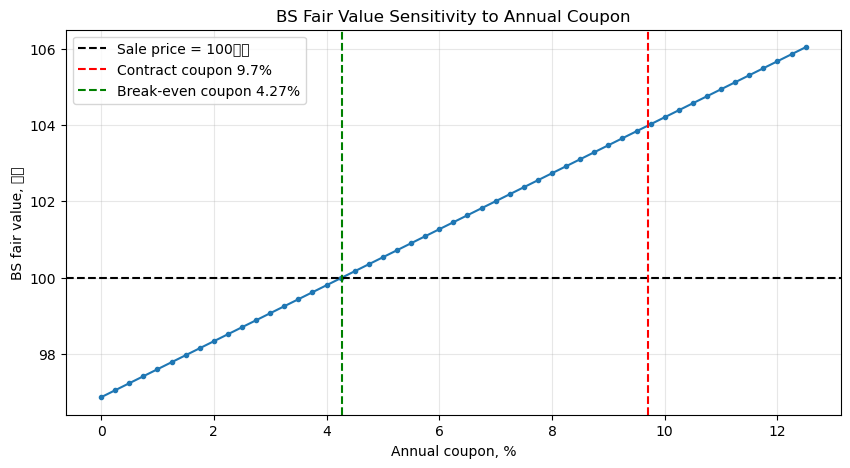

Break-even coupon under this BS setup: 4.2694%
Contract coupon: 9.7000%
Gross issue margin at contract coupon: -3.9812억원


In [7]:
# ============================================================
# 10-7. Coupon Sensitivity around the Contract Coupon
# ============================================================

# 발행마진이 음수라면 상품 조건이 발행사에게 너무 관대한지 확인해야 한다.
# 여기서는 같은 path와 같은 barrier 구조에서 coupon만 바꿨을 때 fair value가 어떻게 변하는지 본다.
def fair_value_for_coupon(coupon):
    payoff_df = calculate_els_payoff(
        paths=rn_paths,
        autocall_schedule=autocall_schedule,
        notional=NOTIONAL,
        S0=S0,
        annual_coupon=coupon,
        knock_in_barrier=KNOCK_IN_BARRIER,
        maturity_years=MATURITY_YEARS,
    )
    discounted = payoff_df["investor_payoff"] * np.exp(-RISK_FREE_RATE * payoff_df["elapsed_years"])
    return discounted.mean()

coupon_grid = np.arange(0.00, 0.125 + 0.0025, 0.0025)
coupon_sensitivity = pd.DataFrame({
    "coupon": coupon_grid,
    "fair_value": [fair_value_for_coupon(c) for c in coupon_grid],
})
coupon_sensitivity["fair_value_100m"] = coupon_sensitivity["fair_value"] / 1e8
coupon_sensitivity["issue_margin_100m"] = (SALE_PRICE - coupon_sensitivity["fair_value"]) / 1e8

# 공정가치가 판매가격 100억원과 같아지는 break-even coupon을 선형보간으로 계산한다.
break_even_coupon = np.interp(
    SALE_PRICE,
    coupon_sensitivity["fair_value"].values,
    coupon_sensitivity["coupon"].values,
)

near_contract = coupon_sensitivity[coupon_sensitivity["coupon"].between(0.06, 0.11)].copy()
near_contract["coupon_pct"] = near_contract["coupon"] * 100

display(near_contract[["coupon_pct", "fair_value_100m", "issue_margin_100m"]].head(25))

plt.figure(figsize=(10, 5))
plt.plot(coupon_sensitivity["coupon"] * 100, coupon_sensitivity["fair_value_100m"], marker="o", markersize=3)
plt.axhline(SALE_PRICE / 1e8, color="black", linestyle="--", label="Sale price = 100억원")
plt.axvline(ANNUAL_COUPON * 100, color="red", linestyle="--", label="Contract coupon 9.7%")
plt.axvline(break_even_coupon * 100, color="green", linestyle="--", label=f"Break-even coupon {break_even_coupon:.2%}")
plt.title("BS Fair Value Sensitivity to Annual Coupon")
plt.xlabel("Annual coupon, %")
plt.ylabel("BS fair value, 억원")
plt.legend()
plt.show()

print(f"Break-even coupon under this BS setup: {break_even_coupon:.4%}")
print(f"Contract coupon: {ANNUAL_COUPON:.4%}")
print(f"Gross issue margin at contract coupon: {GROSS_ISSUE_MARGIN / 1e8:.4f}억원")

## 10-8. Constant Volatility Sensitivity

기본 계산에서는 `q = 0`, `sigma = historical 3y volatility`를 사용했다. 하지만 주가지수 ELS pricing에서는 배당수익률과 변동성 입력이 매우 중요하다.

이 절에서는 같은 payoff 구조를 유지하고, 상수변동성 세계 안에서만 다음을 바꿔 본다.

| 입력 | 의미 |
|---|---|
| `sigma` | 상수변동성 수준. 높아질수록 knock-in과 원금손실 가능성이 커질 수 있다. |
| `q` | 배당수익률. risk-neutral drift를 `r - q`로 낮춘다. |

이 분석은 SABR이나 volatility surface를 쓰지 않는다. 오히려 상수변동성 모델 안에서도 가격이 얼마나 민감한지 보여주기 위한 최소한의 robustness check다.

,sigma_pct,dividend_yield_pct,fair_value_100m,issue_margin_100m,autocall_probability,knock_in_probability,principal_recovery_probability,p05_investor_payoff_100m
0,20.0000,0.0000,104.2409,-4.2409,0.9739,0.0011,0.9997,104.8500
1,20.0000,1.0000,104.2882,-4.2882,0.9696,0.0017,0.9992,104.8500
2,20.0000,2.0000,104.3451,-4.3451,0.9654,0.0025,0.9989,104.8500
3,20.0000,3.0000,104.4126,-4.4126,0.9609,0.0029,0.9987,104.8500
4,20.0000,4.0000,104.4861,-4.4861,0.9548,0.0036,0.9982,104.8500
5,25.0000,0.0000,104.2421,-4.2421,0.9510,0.0135,0.9929,104.8500
6,25.0000,1.0000,104.2282,-4.2282,0.9453,0.0155,0.9916,104.8500
7,25.0000,2.0000,104.2337,-4.2337,0.9388,0.0181,0.9905,104.8500
8,25.0000,3.0000,104.1672,-4.1672,0.9322,0.0219,0.9883,104.8500
9,25.0000,4.0000,104.0610,-4.0610,0.9251,0.0260,0.9858,104.8500


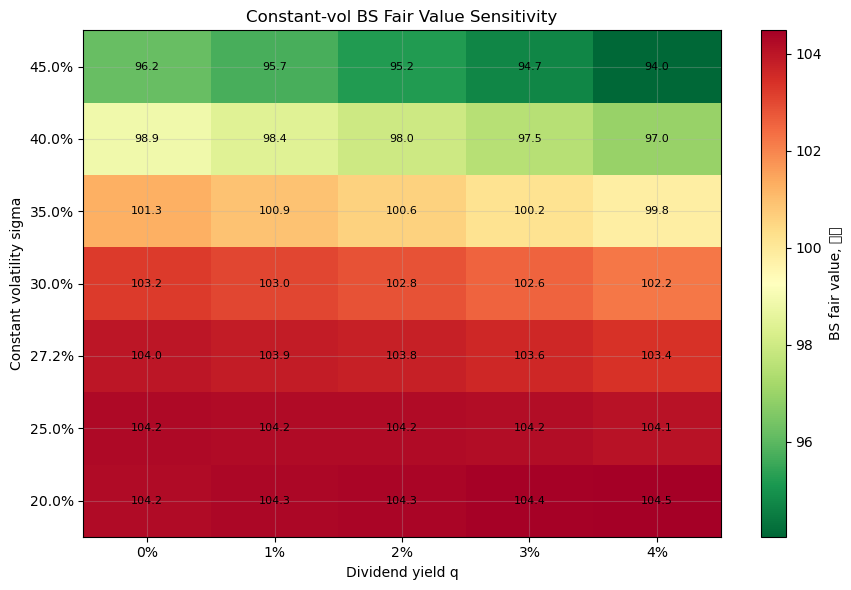

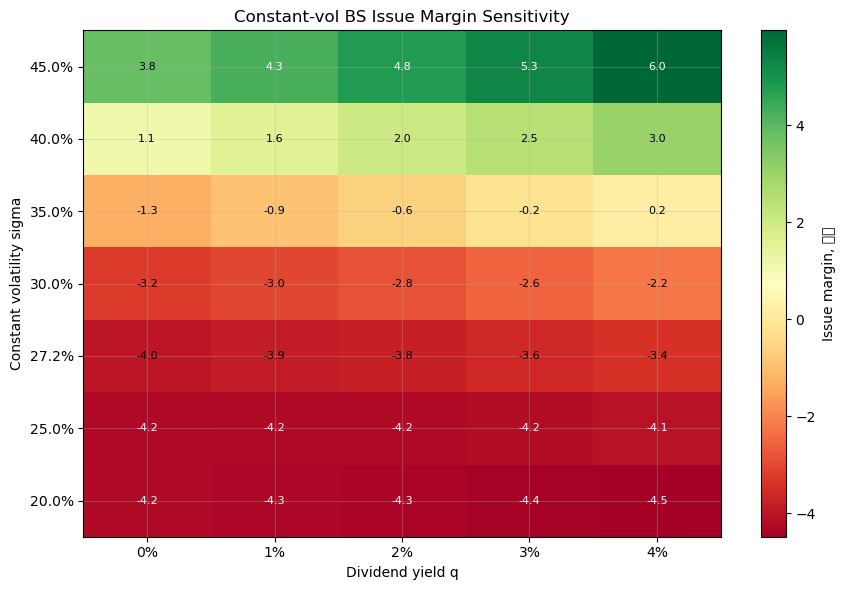

### Fair value가 100억원 이하로 내려가는 상수변동성 시나리오

,sigma_pct,dividend_yield_pct,fair_value_100m,issue_margin_100m,autocall_probability,knock_in_probability,principal_recovery_probability
34,45.0000,4.0000,94.0397,5.9603,0.8247,0.2913,0.8540
33,45.0000,3.0000,94.7157,5.2843,0.8317,0.2782,0.8622
32,45.0000,2.0000,95.2213,4.7787,0.8385,0.2662,0.8686
31,45.0000,1.0000,95.7178,4.2822,0.8441,0.2539,0.8747
30,45.0000,0.0000,96.1991,3.8009,0.8498,0.2421,0.8807
29,40.0000,4.0000,96.9671,3.0329,0.8458,0.2148,0.8890
28,40.0000,3.0000,97.5231,2.4769,0.8523,0.2021,0.8961
27,40.0000,2.0000,97.9974,2.0026,0.8596,0.1905,0.9026
26,40.0000,1.0000,98.4350,1.5650,0.8665,0.1810,0.9084
25,40.0000,0.0000,98.8679,1.1321,0.8732,0.1706,0.9142


In [8]:
# ============================================================
# 10-8. Constant Volatility and Dividend Yield Sensitivity
# ============================================================

# 상수변동성 BS benchmark 안에서 sigma와 dividend yield q만 바꿔 본다.
# 난수 z는 앞에서 만든 risk-neutral path와 같은 것을 재사용한다.
# 이렇게 하면 scenario 간 차이가 Monte Carlo noise가 아니라 입력값 차이에서 주로 나오게 된다.
def price_els_under_constant_vol(sigma, dividend_yield):
    '''
    상수변동성 sigma와 배당수익률 q를 입력받아 ELS fair value를 계산한다.

    risk-neutral drift는 r - q를 사용한다.
    '''
    log_increment = (
        (RISK_FREE_RATE - dividend_yield - 0.5 * sigma ** 2) * DT
        + sigma * np.sqrt(DT) * z
    )

    scenario_paths = np.empty_like(rn_paths)
    scenario_paths[:, 0] = S0
    scenario_paths[:, 1:] = S0 * np.exp(np.cumsum(log_increment, axis=1))

    scenario_payoff = calculate_els_payoff(
        paths=scenario_paths,
        autocall_schedule=autocall_schedule,
        notional=NOTIONAL,
        S0=S0,
        annual_coupon=ANNUAL_COUPON,
        knock_in_barrier=KNOCK_IN_BARRIER,
        maturity_years=MATURITY_YEARS,
    )

    discounted_payoff = (
        scenario_payoff["investor_payoff"]
        * np.exp(-RISK_FREE_RATE * scenario_payoff["elapsed_years"])
    )

    return {
        "sigma": sigma,
        "dividend_yield": dividend_yield,
        "fair_value": discounted_payoff.mean(),
        "issue_margin": SALE_PRICE - discounted_payoff.mean(),
        "autocall_probability": scenario_payoff["autocall_occurred"].mean(),
        "knock_in_probability": scenario_payoff["knock_in_occurred"].mean(),
        "principal_recovery_probability": (scenario_payoff["investor_payoff"] >= NOTIONAL).mean(),
        "p05_investor_payoff": np.percentile(scenario_payoff["investor_payoff"], 5),
    }


sigma_grid = np.array([0.20, 0.25, SIGMA, 0.30, 0.35, 0.40, 0.45])
q_grid = np.array([0.00, 0.01, 0.02, 0.03, 0.04])

sensitivity_rows = []
for sigma_value in sigma_grid:
    for q_value in q_grid:
        sensitivity_rows.append(price_els_under_constant_vol(sigma_value, q_value))

constant_vol_sensitivity = pd.DataFrame(sensitivity_rows)
constant_vol_sensitivity["sigma_pct"] = constant_vol_sensitivity["sigma"] * 100
constant_vol_sensitivity["dividend_yield_pct"] = constant_vol_sensitivity["dividend_yield"] * 100
constant_vol_sensitivity["fair_value_100m"] = constant_vol_sensitivity["fair_value"] / 1e8
constant_vol_sensitivity["issue_margin_100m"] = constant_vol_sensitivity["issue_margin"] / 1e8
constant_vol_sensitivity["p05_investor_payoff_100m"] = constant_vol_sensitivity["p05_investor_payoff"] / 1e8

display(
    constant_vol_sensitivity[
        [
            "sigma_pct", "dividend_yield_pct", "fair_value_100m",
            "issue_margin_100m", "autocall_probability",
            "knock_in_probability", "principal_recovery_probability",
            "p05_investor_payoff_100m",
        ]
    ].sort_values(["sigma_pct", "dividend_yield_pct"])
)

# Heatmap 1: fair value
fair_value_pivot = constant_vol_sensitivity.pivot_table(
    index="sigma_pct",
    columns="dividend_yield_pct",
    values="fair_value_100m",
)

plt.figure(figsize=(9, 6))
plt.imshow(fair_value_pivot.values, aspect="auto", origin="lower", cmap="RdYlGn_r")
plt.colorbar(label="BS fair value, 억원")
plt.xticks(range(len(fair_value_pivot.columns)), [f"{x:.0f}%" for x in fair_value_pivot.columns])
plt.yticks(range(len(fair_value_pivot.index)), [f"{x:.1f}%" for x in fair_value_pivot.index])
plt.xlabel("Dividend yield q")
plt.ylabel("Constant volatility sigma")
plt.title("Constant-vol BS Fair Value Sensitivity")
for y in range(fair_value_pivot.shape[0]):
    for x in range(fair_value_pivot.shape[1]):
        value = fair_value_pivot.values[y, x]
        plt.text(x, y, f"{value:.1f}", ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.show()

# Heatmap 2: issue margin
margin_pivot = constant_vol_sensitivity.pivot_table(
    index="sigma_pct",
    columns="dividend_yield_pct",
    values="issue_margin_100m",
)

plt.figure(figsize=(9, 6))
plt.imshow(margin_pivot.values, aspect="auto", origin="lower", cmap="RdYlGn")
plt.colorbar(label="Issue margin, 억원")
plt.xticks(range(len(margin_pivot.columns)), [f"{x:.0f}%" for x in margin_pivot.columns])
plt.yticks(range(len(margin_pivot.index)), [f"{x:.1f}%" for x in margin_pivot.index])
plt.xlabel("Dividend yield q")
plt.ylabel("Constant volatility sigma")
plt.title("Constant-vol BS Issue Margin Sensitivity")
for y in range(margin_pivot.shape[0]):
    for x in range(margin_pivot.shape[1]):
        value = margin_pivot.values[y, x]
        color = "white" if abs(value) > 4 else "black"
        plt.text(x, y, f"{value:.1f}", ha="center", va="center", fontsize=8, color=color)
plt.tight_layout()
plt.show()

# 판매가격 100억원 이하로 내려가는 시나리오만 별도 확인한다.
positive_margin_cases = constant_vol_sensitivity[
    constant_vol_sensitivity["issue_margin"] > 0
].copy()

display(Markdown("### Fair value가 100억원 이하로 내려가는 상수변동성 시나리오"))
if len(positive_margin_cases) == 0:
    display(Markdown("현재 sensitivity grid 안에서는 양의 발행마진이 나오지 않는다."))
else:
    display(
        positive_margin_cases[
            [
                "sigma_pct", "dividend_yield_pct", "fair_value_100m",
                "issue_margin_100m", "autocall_probability",
                "knock_in_probability", "principal_recovery_probability",
            ]
        ].sort_values("issue_margin_100m", ascending=False)
    )

### 10-8 해석

이 민감도 표는 “미래에셋이 손해나는 상품을 판다”는 결론을 내기 위한 것이 아니다. 오히려 현재 단순모형이 실제 발행가를 설명하기 어려운 이유를 보여준다.

- `sigma = 27.2%`, `q = 0%`에서는 fair value가 100억원보다 높게 나올 수 있다.
- 더 높은 volatility 또는 양의 배당수익률을 넣으면 fair value가 낮아질 수 있다.
- 실제 발행사는 단일 historical volatility가 아니라 volatility surface, 배당률, funding, credit, hedge cost, 시장 bid-ask 등을 함께 반영한다.
- 따라서 Section 10의 BS 가격은 실제 공정가의 대체물이 아니라, 발행마진 가정이 모델 입력에 얼마나 민감한지 확인하는 benchmark다.

## 10-8. 발행마진과 운용성과 연결

위 fair value는 발행 시점의 이론가격이다. 이제 이 값을 기존 운용성과와 연결한다.

- 기존 Section 7~9의 terminal balance는 실제 운용 계좌 관점이다.
- 여기서는 동적헤지 거래비용을 30bp로 고정하여 pathwise dynamic hedge account를 다시 계산한다.
- 새 파일은 저장하지 않고, 계산된 행렬은 노트북 메모리 안에서만 사용한다.

중요한 구분:

| 개념 | 의미 |
|---|---|
| Investor principal recovery probability | 상품 payoff 자체의 원금회수 확률. 같은 상품이면 헤지전략별로 달라지지 않는다. |
| Issuer no-shortfall probability | payoff 지급, 헤지 손익, 비용 반영 후 발행사 terminal balance가 음수가 아닐 확률. 헤지전략별로 달라진다. |

In [9]:
# ============================================================
# 10-9. Growth Factors and Existing Account Components
# ============================================================

# 기존 Section 9와 같은 방식으로 settlement 시점별 현금흐름을 만기 가치로 환산한다.
def cash_growth_factor_by_calendar_days(n_days, daily_rate=PRINCIPAL_DAILY_RATE):
    '''캘린더 일수 기준 현금성 계좌 성장계수.'''
    return (1 + daily_rate) ** n_days

n_paths = len(payoff_df_real)
n_experiments = len(experiment_grid)

settlement_index = payoff_df_real["settlement_index"].astype(int).values
issuer_cash_outflow = payoff_df_real["issuer_cash_outflow"].astype(float).values

issue_date = sim_dates[0]
final_date = sim_dates[-1]
settlement_dates = sim_dates[settlement_index]

days_settlement_to_maturity = np.array([(final_date - d).days for d in settlement_dates])
total_days_to_maturity = (final_date - issue_date).days

growth_settlement_to_maturity = cash_growth_factor_by_calendar_days(days_settlement_to_maturity)
growth_full_maturity = cash_growth_factor_by_calendar_days(total_days_to_maturity)

# 원금북, 정적헤지 계좌, payoff 차감액을 명확하게 분리한다.
principal_account_terminal_matrix = np.zeros((n_experiments, n_paths))
static_hedge_account_terminal_matrix = np.zeros((n_experiments, n_paths))
payoff_terminal_equivalent_matrix = np.zeros((n_experiments, n_paths))

for i, row in experiment_grid.iterrows():
    principal_amount = float(row["principal_book_amount"])
    static_budget = float(row["static_budget"])

    # 원금북은 채권/현금성 계좌처럼 만기까지 운용된다고 본다.
    principal_account_terminal_matrix[i, :] = principal_amount * growth_full_maturity

    # 정적헤지 계좌는 static budget의 현금 담보 성장분과 short put 손익을 더한다.
    static_cash_collateral_terminal = static_budget * growth_full_maturity
    static_hedge_account_terminal_matrix[i, :] = (
        static_cash_collateral_terminal + static_pnl_terminal_matrix[i, :]
    )

    # payoff는 settlement 시점 지급액을 만기시점 가치로 환산하여 차감한다.
    payoff_terminal_equivalent_matrix[i, :] = issuer_cash_outflow * growth_settlement_to_maturity

component_check = pd.DataFrame({
    "metric": ["issue_date", "final_date", "total_calendar_days", "growth_full_maturity"],
    "value": [str(issue_date.date()), str(final_date.date()), total_days_to_maturity, growth_full_maturity],
})

display(component_check)

,metric,value
0,issue_date,2026-05-14
1,final_date,2029-05-09
2,total_calendar_days,1091
3,growth_full_maturity,1.0938


In [10]:
# ============================================================
# 10-10. Dynamic Hedge Account with 30bp Transaction Cost
# ============================================================

# 동적헤지 비용은 사용자 조건대로 30bp를 유지한다.
# 거래비용은 리밸런싱 때마다 abs(trade notional) * 30bp로 cash account에서 직접 차감한다.
def lookup_delta_vectorized(S_values, time_index, ki_states):
    '''FDM delta grid에서 현재 가격과 KI 상태에 맞는 delta를 보간한다.'''
    time_index = int(np.clip(time_index, 0, delta_ki_grid.shape[0] - 1))
    S_clipped = np.clip(S_values, S_GRID[0], S_GRID[-1])
    delta_noki = np.interp(S_clipped, S_GRID, delta_noki_grid[time_index, :])
    delta_ki = np.interp(S_clipped, S_GRID, delta_ki_grid[time_index, :])
    return np.where(ki_states, delta_ki, delta_noki)

ki_state_matrix = np.minimum.accumulate(existing_paths, axis=1) <= (KNOCK_IN_BARRIER * S0)
existing_n_paths, existing_n_time = existing_paths.shape
existing_n_steps = existing_n_time - 1

weekly_rebal_indices = np.arange(0, existing_n_steps + 1, 5)
settlement_indices = payoff_df_real["settlement_index"].astype(int).unique()
trading_indices = np.unique(np.concatenate([weekly_rebal_indices, settlement_indices, np.array([existing_n_steps])]))
trading_indices = np.sort(trading_indices)


def run_dynamic_hedge_with_tc(row, transaction_cost_bps=DYNAMIC_TC_BPS):
    '''
    한 전략(row)에 대해 30bp 거래비용을 반영한 동적헤지 현금계좌를 pathwise 계산한다.

    반환값:
    - cash: path별 최종 동적헤지 계좌 잔고
    - transaction_cost_paid: path별 누적 거래비용
    - turnover: path별 누적 거래금액
    '''
    dynamic_ratio = float(row["dynamic_ratio"])
    dynamic_budget = float(row["dynamic_budget"])
    tc_rate = transaction_cost_bps * 1e-4

    cash = np.full(existing_n_paths, dynamic_budget, dtype=float)
    units = np.zeros(existing_n_paths, dtype=float)
    active = np.ones(existing_n_paths, dtype=bool)

    transaction_cost_paid = np.zeros(existing_n_paths)
    turnover = np.zeros(existing_n_paths)
    last_idx = 0

    for idx in trading_indices:
        idx = int(idx)

        # 직전 거래일 이후 경과 기간 동안 현금계좌는 일복리로 성장한다.
        n_days = idx - last_idx
        if n_days > 0:
            cash *= cash_growth_factor_by_calendar_days(n_days)

        S_t = existing_paths[:, idx]

        # 조기상환 또는 만기 settlement 시점에는 기존 포지션을 청산한다.
        settle_now = active & (settlement_index == idx)
        if np.any(settle_now):
            close_notional = np.abs(units[settle_now] * S_t[settle_now])
            close_cost = tc_rate * close_notional
            cash[settle_now] += units[settle_now] * S_t[settle_now]
            cash[settle_now] -= close_cost
            transaction_cost_paid[settle_now] += close_cost
            turnover[settle_now] += close_notional
            units[settle_now] = 0.0
            active[settle_now] = False

        # 아직 살아있는 path는 FDM delta에 맞춰 hedge position을 리밸런싱한다.
        rebalance_now = active
        if np.any(rebalance_now):
            S_active = S_t[rebalance_now]
            ki_active = ki_state_matrix[rebalance_now, idx]
            liability_delta = lookup_delta_vectorized(S_active, idx, ki_active)

            target_units_uncapped = liability_delta * dynamic_ratio
            position_value_uncapped = target_units_uncapped * S_active
            abs_position_value = np.abs(position_value_uncapped)

            # hedge budget을 넘는 포지션은 budget 한도 안으로 축소한다.
            cap_factor = np.ones_like(target_units_uncapped)
            binding = abs_position_value > dynamic_budget
            cap_factor[binding] = dynamic_budget / (abs_position_value[binding] + 1e-12)
            target_units = target_units_uncapped * cap_factor

            old_units = units[rebalance_now]
            trade_units = target_units - old_units
            trade_notional = np.abs(trade_units * S_active)
            transaction_cost = tc_rate * trade_notional

            cash[rebalance_now] -= trade_units * S_active
            cash[rebalance_now] -= transaction_cost
            units[rebalance_now] = target_units
            transaction_cost_paid[rebalance_now] += transaction_cost
            turnover[rebalance_now] += trade_notional

        last_idx = idx

    # 만기까지 살아있는 path는 마지막 가격으로 남은 hedge position을 청산한다.
    final_S = existing_paths[:, -1]
    still_active = active
    if np.any(still_active):
        close_notional = np.abs(units[still_active] * final_S[still_active])
        close_cost = (transaction_cost_bps * 1e-4) * close_notional
        cash[still_active] += units[still_active] * final_S[still_active]
        cash[still_active] -= close_cost
        transaction_cost_paid[still_active] += close_cost
        turnover[still_active] += close_notional

    return cash, transaction_cost_paid, turnover


# 모든 전략에 대해 pathwise 30bp 동적헤지 계좌를 계산한다.
dynamic_30bp_account_matrix = np.zeros((n_experiments, n_paths))
dynamic_30bp_cost_matrix = np.zeros((n_experiments, n_paths))
dynamic_turnover_matrix = np.zeros((n_experiments, n_paths))

for i, row in experiment_grid.iterrows():
    cash, tc_paid, turnover = run_dynamic_hedge_with_tc(row, transaction_cost_bps=DYNAMIC_TC_BPS)
    dynamic_30bp_account_matrix[i, :] = cash
    dynamic_30bp_cost_matrix[i, :] = tc_paid
    dynamic_turnover_matrix[i, :] = turnover

cost_check = pd.DataFrame({
    "metric": ["dynamic_tc_bps", "mean_dynamic_tc_paid", "p95_dynamic_tc_paid", "mean_turnover"],
    "value_100m": [
        DYNAMIC_TC_BPS,
        dynamic_30bp_cost_matrix.mean() / 1e8,
        np.percentile(dynamic_30bp_cost_matrix, 95) / 1e8,
        dynamic_turnover_matrix.mean() / 1e8,
    ],
})

display(cost_check)

,metric,value_100m
0,dynamic_tc_bps,30.0000
1,mean_dynamic_tc_paid,0.1684
2,p95_dynamic_tc_paid,0.9273
3,mean_turnover,56.1177


In [11]:
# ============================================================
# 10-11. BS Issue Margin, Sales Fee, and Strategy Summary
# ============================================================

# 30bp 동적헤지 비용을 반영한 발행사 terminal balance를 먼저 만든다.
# 아직 BS issue margin은 더하지 않은 상태다.
base_terminal_30bp_matrix = (
    principal_account_terminal_matrix
    + static_hedge_account_terminal_matrix
    + dynamic_30bp_account_matrix
    - payoff_terminal_equivalent_matrix
)

# 판매수수료는 발행사가 t=0에 판매채널에 지급하는 비용으로 본다.
# gross issue margin에서 차감한 뒤 만기까지 현금성 계좌로 운용한다.
SALES_FEE_RATES = [0.000, 0.005, 0.010]

pricing_margin_rows = []
strategy_rows = []

for fee_rate in SALES_FEE_RATES:
    sales_fee = SALE_PRICE * fee_rate
    net_issue_margin = GROSS_ISSUE_MARGIN - sales_fee
    net_issue_margin_terminal = net_issue_margin * growth_full_maturity

    pricing_margin_rows.append({
        "sales_fee_rate": fee_rate,
        "bs_fair_value_100m": ELS_FAIR_VALUE / 1e8,
        "gross_issue_margin_100m": GROSS_ISSUE_MARGIN / 1e8,
        "sales_fee_100m": sales_fee / 1e8,
        "net_issue_margin_100m": net_issue_margin / 1e8,
        "net_issue_margin_terminal_100m": net_issue_margin_terminal / 1e8,
    })

    scenario_matrix = base_terminal_30bp_matrix + net_issue_margin_terminal

    for i, row in experiment_grid.iterrows():
        tb = scenario_matrix[i, :]
        p05 = np.percentile(tb, 5)
        cvar05 = tb[tb <= p05].mean()

        strategy_rows.append({
            "sales_fee_rate": fee_rate,
            "experiment_id": int(row["experiment_id"]),
            "principal_book_ratio": float(row["principal_book_ratio"]),
            "hedge_book_ratio": float(row["hedge_book_ratio"]),
            "static_ratio": float(row["static_ratio"]),
            "dynamic_ratio": float(row["dynamic_ratio"]),
            "static_budget_100m": float(row["static_budget"]) / 1e8,
            "dynamic_budget_100m": float(row["dynamic_budget"]) / 1e8,
            "gross_issue_margin_100m": GROSS_ISSUE_MARGIN / 1e8,
            "sales_fee_100m": sales_fee / 1e8,
            "net_issue_margin_terminal_100m": net_issue_margin_terminal / 1e8,
            "mean_dynamic_tc_paid_100m": dynamic_30bp_cost_matrix[i, :].mean() / 1e8,
            "p95_dynamic_tc_paid_100m": np.percentile(dynamic_30bp_cost_matrix[i, :], 95) / 1e8,
            "mean_terminal_balance_100m": tb.mean() / 1e8,
            "p05_terminal_balance_100m": p05 / 1e8,
            "cvar05_terminal_balance_100m": cvar05 / 1e8,
            "issuer_no_shortfall_probability": np.mean(tb >= 0),
            "capital_required_95_100m": max(-p05, 0) / 1e8,
        })

pricing_margin_table = pd.DataFrame(pricing_margin_rows)
strategy_summary = pd.DataFrame(strategy_rows)

# 상품 payoff 자체의 투자자 원금회수 확률은 hedge strategy와 무관하므로 별도로 보여준다.
investor_protection_table = pd.DataFrame([{
    "principal_recovery_probability_real_paths": np.mean(payoff_df_real["investor_payoff"] >= NOTIONAL),
    "loss_probability_real_paths": np.mean(payoff_df_real["investor_payoff"] < NOTIONAL),
    "autocall_probability_real_paths": np.mean(payoff_df_real["autocall_occurred"]),
    "knock_in_probability_real_paths": np.mean(payoff_df_real["knock_in_occurred"]),
    "mean_investor_payoff_100m_real_paths": payoff_df_real["investor_payoff"].mean() / 1e8,
    "p05_investor_payoff_100m_real_paths": np.percentile(payoff_df_real["investor_payoff"], 5) / 1e8,
}])

display(Markdown("### BS fair value에서 출발한 발행마진"))
display(pricing_margin_table)

display(Markdown("### 투자자 payoff 자체의 원금회수 지표"))
display(investor_protection_table)

### BS fair value에서 출발한 발행마진

,sales_fee_rate,bs_fair_value_100m,gross_issue_margin_100m,sales_fee_100m,net_issue_margin_100m,net_issue_margin_terminal_100m
0,0.0000,103.9812,-3.9812,0.0000,-3.9812,-4.3547
1,0.0050,103.9812,-3.9812,0.5000,-4.4812,-4.9016
2,0.0100,103.9812,-3.9812,1.0000,-4.9812,-5.4485


### 투자자 payoff 자체의 원금회수 지표

,principal_recovery_probability_real_paths,loss_probability_real_paths,autocall_probability_real_paths,knock_in_probability_real_paths,mean_investor_payoff_100m_real_paths,p05_investor_payoff_100m_real_paths
0,0.9870,0.0130,0.9412,0.0264,106.5371,104.8500


In [12]:
# ============================================================
# 10-12. Strategy Ranking under 30bp Dynamic Hedge Cost
# ============================================================

# base case로 판매수수료 0.5%를 둔다.
BASE_FEE_RATE = 0.005
base_strategy = strategy_summary[strategy_summary["sales_fee_rate"] == BASE_FEE_RATE].copy()

rank_by_mean = base_strategy.sort_values("mean_terminal_balance_100m", ascending=False).head(10)
rank_by_p05 = base_strategy.sort_values("p05_terminal_balance_100m", ascending=False).head(10)
rank_by_shortfall = base_strategy.sort_values("issuer_no_shortfall_probability", ascending=False).head(10)

show_cols = [
    "experiment_id", "principal_book_ratio", "hedge_book_ratio",
    "static_ratio", "dynamic_ratio", "net_issue_margin_terminal_100m",
    "mean_dynamic_tc_paid_100m", "mean_terminal_balance_100m",
    "p05_terminal_balance_100m", "cvar05_terminal_balance_100m",
    "issuer_no_shortfall_probability", "capital_required_95_100m",
]

display(Markdown("### Top 10 by mean terminal balance, sales fee 0.5%"))
display(rank_by_mean[show_cols])

display(Markdown("### Top 10 by 5% terminal balance, sales fee 0.5%"))
display(rank_by_p05[show_cols])

display(Markdown("### Top 10 by issuer no-shortfall probability, sales fee 0.5%"))
display(rank_by_shortfall[show_cols])

### Top 10 by mean terminal balance, sales fee 0.5%

,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,net_issue_margin_terminal_100m,mean_dynamic_tc_paid_100m,mean_terminal_balance_100m,p05_terminal_balance_100m,cvar05_terminal_balance_100m,issuer_no_shortfall_probability,capital_required_95_100m
43,10,0.3000,0.7000,1.0000,0.0000,-4.9016,0.0000,-9.2088,-20.8956,-34.0700,0.0130,20.8956
54,21,0.5000,0.5000,1.0000,0.0000,-4.9016,0.0000,-9.2238,-21.8239,-31.7152,0.0130,21.8239
65,32,0.7000,0.3000,1.0000,0.0000,-4.9016,0.0000,-9.2419,-22.9425,-28.8773,0.0130,22.9425
64,31,0.7000,0.3000,0.9000,0.1000,-4.9016,0.0276,-9.3553,-22.7803,-29.5075,0.0130,22.7803
53,20,0.5000,0.5000,0.9000,0.1000,-4.9016,0.0343,-9.3993,-21.6557,-32.7058,0.0130,21.6557
42,9,0.3000,0.7000,0.9000,0.1000,-4.9016,0.0390,-9.4437,-20.7486,-35.2964,0.0130,20.7486
63,30,0.7000,0.3000,0.8000,0.2000,-4.9016,0.0553,-9.4687,-22.4180,-29.1159,0.0130,22.4180
52,19,0.5000,0.5000,0.8000,0.2000,-4.9016,0.0687,-9.5747,-21.3955,-31.9853,0.0130,21.3955
62,29,0.7000,0.3000,0.7000,0.3000,-4.9016,0.0829,-9.5820,-22.1436,-28.7323,0.0130,22.1436
41,8,0.3000,0.7000,0.8000,0.2000,-4.9016,0.0781,-9.6786,-20.4649,-34.2364,0.0130,20.4649


### Top 10 by 5% terminal balance, sales fee 0.5%

,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,net_issue_margin_terminal_100m,mean_dynamic_tc_paid_100m,mean_terminal_balance_100m,p05_terminal_balance_100m,cvar05_terminal_balance_100m,issuer_no_shortfall_probability,capital_required_95_100m
33,0,0.3000,0.7000,0.0000,1.0000,-4.9016,0.3903,-11.5577,-16.7180,-26.6805,0.0130,16.7180
44,11,0.5000,0.5000,0.0000,1.0000,-4.9016,0.3434,-10.9784,-17.1446,-27.1017,0.0130,17.1446
34,1,0.3000,0.7000,0.1000,0.9000,-4.9016,0.3513,-11.3228,-17.3582,-27.4048,0.0130,17.3582
45,12,0.5000,0.5000,0.1000,0.9000,-4.9016,0.3090,-10.8030,-17.8528,-27.5706,0.0130,17.8528
35,2,0.3000,0.7000,0.2000,0.8000,-4.9016,0.3123,-11.0879,-18.0839,-28.2456,0.0130,18.0839
46,13,0.5000,0.5000,0.2000,0.8000,-4.9016,0.2747,-10.6275,-18.6405,-28.0897,0.0130,18.6405
36,3,0.3000,0.7000,0.3000,0.7000,-4.9016,0.2732,-10.8530,-18.7212,-29.1694,0.0130,18.7212
55,22,0.7000,0.3000,0.0000,1.0000,-4.9016,0.2764,-10.3756,-18.9437,-26.7059,0.0130,18.9437
37,4,0.3000,0.7000,0.4000,0.6000,-4.9016,0.2342,-10.6181,-19.1504,-30.1379,0.0130,19.1504
47,14,0.5000,0.5000,0.3000,0.7000,-4.9016,0.2404,-10.4520,-19.3169,-28.6651,0.0130,19.3169


### Top 10 by issuer no-shortfall probability, sales fee 0.5%

,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,net_issue_margin_terminal_100m,mean_dynamic_tc_paid_100m,mean_terminal_balance_100m,p05_terminal_balance_100m,cvar05_terminal_balance_100m,issuer_no_shortfall_probability,capital_required_95_100m
33,0,0.3000,0.7000,0.0000,1.0000,-4.9016,0.3903,-11.5577,-16.7180,-26.6805,0.0130,16.7180
50,17,0.5000,0.5000,0.6000,0.4000,-4.9016,0.1373,-9.9257,-20.8532,-30.5866,0.0130,20.8532
64,31,0.7000,0.3000,0.9000,0.1000,-4.9016,0.0276,-9.3553,-22.7803,-29.5075,0.0130,22.7803
63,30,0.7000,0.3000,0.8000,0.2000,-4.9016,0.0553,-9.4687,-22.4180,-29.1159,0.0130,22.4180
62,29,0.7000,0.3000,0.7000,0.3000,-4.9016,0.0829,-9.5820,-22.1436,-28.7323,0.0130,22.1436
61,28,0.7000,0.3000,0.6000,0.4000,-4.9016,0.1106,-9.6954,-21.6848,-28.3661,0.0130,21.6848
60,27,0.7000,0.3000,0.5000,0.5000,-4.9016,0.1382,-9.8087,-21.3704,-28.0255,0.0130,21.3704
59,26,0.7000,0.3000,0.4000,0.6000,-4.9016,0.1659,-9.9221,-20.9160,-27.7076,0.0130,20.9160
58,25,0.7000,0.3000,0.3000,0.7000,-4.9016,0.1935,-10.0355,-20.4060,-27.4183,0.0130,20.4060
57,24,0.7000,0.3000,0.2000,0.8000,-4.9016,0.2211,-10.1488,-19.9701,-27.1583,0.0130,19.9701


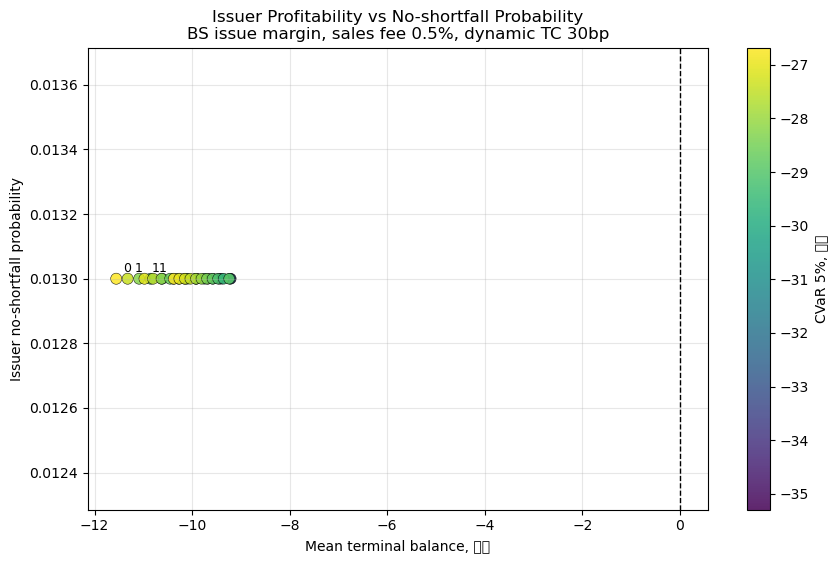

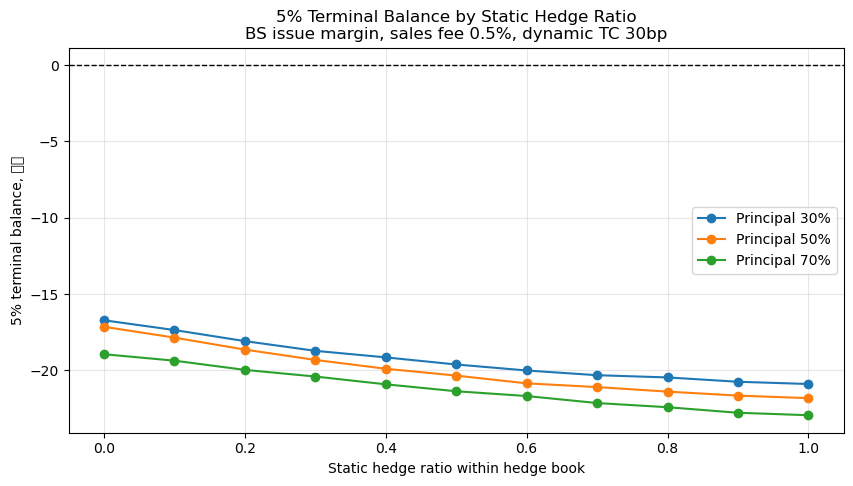

In [13]:
# ============================================================
# 10-13. Profit vs Shortfall Trade-off Plot
# ============================================================

# x축은 발행사 평균 terminal balance, y축은 발행사 shortfall이 발생하지 않을 확률이다.
# 투자자 원금회수 확률은 같은 상품이면 전략별로 변하지 않으므로 별도 표에서 확인한다.
plot_df = base_strategy.copy()

plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    plot_df["mean_terminal_balance_100m"],
    plot_df["issuer_no_shortfall_probability"],
    c=plot_df["cvar05_terminal_balance_100m"],
    s=60 + 10 * plot_df["mean_dynamic_tc_paid_100m"].clip(lower=0),
    cmap="viridis",
    alpha=0.85,
    edgecolor="black",
    linewidth=0.4,
)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("Issuer Profitability vs No-shortfall Probability\nBS issue margin, sales fee 0.5%, dynamic TC 30bp")
plt.xlabel("Mean terminal balance, 억원")
plt.ylabel("Issuer no-shortfall probability")
cbar = plt.colorbar(scatter)
cbar.set_label("CVaR 5%, 억원")

for _, row in plot_df.iterrows():
    if row["experiment_id"] in rank_by_p05["experiment_id"].head(3).values:
        plt.annotate(
            int(row["experiment_id"]),
            (row["mean_terminal_balance_100m"], row["issuer_no_shortfall_probability"]),
            textcoords="offset points",
            xytext=(5, 5),
            fontsize=9,
        )

plt.show()

plt.figure(figsize=(10, 5))
for principal_ratio, temp in plot_df.groupby("principal_book_ratio"):
    temp = temp.sort_values("static_ratio")
    plt.plot(
        temp["static_ratio"],
        temp["p05_terminal_balance_100m"],
        marker="o",
        label=f"Principal {principal_ratio:.0%}",
    )
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("5% Terminal Balance by Static Hedge Ratio\nBS issue margin, sales fee 0.5%, dynamic TC 30bp")
plt.xlabel("Static hedge ratio within hedge book")
plt.ylabel("5% terminal balance, 억원")
plt.legend()
plt.show()

Recommended tail strategy: experiment 0, principal 30%, static 0%, dynamic 100%


,payoff_type,count,mean_min_price,mean_final_price,mean_investor_payoff_100m,mean_dynamic_tc_paid_100m,mean_terminal_balance_100m
0,autocall_2,5,75.8536,128.1807,109.7000,0.7208,-17.8137
1,autocall_3,10,68.4661,98.6775,114.5500,1.2265,-18.0821
2,autocall_4,19,59.3473,93.9387,119.4000,1.5765,-18.1428
3,autocall_5,50,53.2944,90.5796,124.2500,2.0310,-19.4189
4,autocall_6,70,49.5983,79.9056,129.1000,2.2639,-21.5366
5,maturity_no_knock_in,346,42.5588,51.3076,129.1000,2.5928,-29.6160


,path_id,payoff_type,autocall_no,knock_in_occurred,min_price,final_price,investor_payoff_100m,payoff_terminal_equivalent_100m,dynamic_tc_paid_100m,terminal_balance_100m,is_bottom_5pct
45,45,maturity_no_knock_in,0,False,39.0174,47.9958,129.1000,129.1000,2.4768,-37.9126,True
92,92,autocall_4,4,False,45.1640,79.3113,119.4000,123.0361,1.5790,-18.4974,True
147,147,maturity_no_knock_in,0,False,35.4528,57.2939,129.1000,129.1000,1.8638,-38.9072,True
170,170,maturity_no_knock_in,0,False,45.5696,68.7058,129.1000,129.1000,3.1926,-18.2574,True
207,207,maturity_no_knock_in,0,False,36.7829,45.8514,129.1000,129.1000,3.0983,-30.4950,True
211,211,maturity_no_knock_in,0,False,46.1687,47.5173,129.1000,129.1000,2.8839,-24.6805,True
217,217,autocall_6,6,False,45.1294,76.8554,129.1000,129.1000,1.9608,-27.5384,True
234,234,maturity_no_knock_in,0,False,39.8806,41.9272,129.1000,129.1000,3.0250,-21.3025,True
271,271,maturity_no_knock_in,0,False,36.3015,41.3003,129.1000,129.1000,3.2839,-31.6008,True
306,306,maturity_no_knock_in,0,False,35.6467,37.8075,129.1000,129.1000,2.8812,-45.7786,True


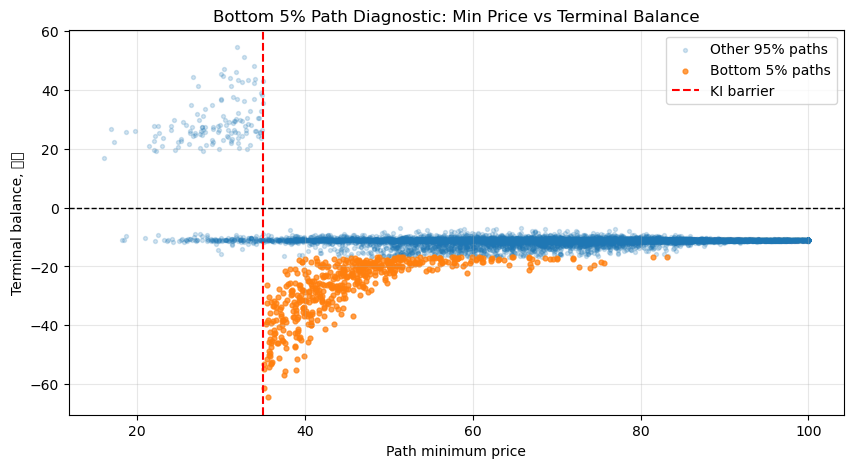

In [14]:
# ============================================================
# 10-14. Bottom 5% Path Diagnostics for the Recommended Tail Strategy
# ============================================================

# tail 관점에서는 p05 terminal balance가 가장 높은 전략을 대표 전략으로 본다.
recommended_id = int(rank_by_p05.iloc[0]["experiment_id"])
recommended_row = experiment_grid.loc[recommended_id]

base_fee = SALE_PRICE * BASE_FEE_RATE
net_issue_margin = GROSS_ISSUE_MARGIN - base_fee
net_issue_margin_terminal = net_issue_margin * growth_full_maturity

recommended_tb = base_terminal_30bp_matrix[recommended_id, :] + net_issue_margin_terminal
bottom_threshold = np.percentile(recommended_tb, 5)
bottom_mask = recommended_tb <= bottom_threshold

bottom_path_df = pd.DataFrame({
    "path_id": payoff_df_real["path_id"],
    "payoff_type": payoff_df_real["payoff_type"],
    "autocall_no": payoff_df_real["autocall_no"],
    "knock_in_occurred": payoff_df_real["knock_in_occurred"],
    "min_price": payoff_df_real["min_price"],
    "final_price": payoff_df_real["final_price"],
    "investor_payoff_100m": payoff_df_real["investor_payoff"] / 1e8,
    "payoff_terminal_equivalent_100m": payoff_terminal_equivalent_matrix[recommended_id, :] / 1e8,
    "dynamic_tc_paid_100m": dynamic_30bp_cost_matrix[recommended_id, :] / 1e8,
    "terminal_balance_100m": recommended_tb / 1e8,
    "is_bottom_5pct": bottom_mask,
})

bottom_summary = (
    bottom_path_df[bottom_path_df["is_bottom_5pct"]]
    .groupby("payoff_type")
    .agg(
        count=("path_id", "count"),
        mean_min_price=("min_price", "mean"),
        mean_final_price=("final_price", "mean"),
        mean_investor_payoff_100m=("investor_payoff_100m", "mean"),
        mean_dynamic_tc_paid_100m=("dynamic_tc_paid_100m", "mean"),
        mean_terminal_balance_100m=("terminal_balance_100m", "mean"),
    )
    .reset_index()
)

strategy_label = (
    f"experiment {recommended_id}, principal {recommended_row['principal_book_ratio']:.0%}, "
    f"static {recommended_row['static_ratio']:.0%}, dynamic {recommended_row['dynamic_ratio']:.0%}"
)

print("Recommended tail strategy:", strategy_label)
display(bottom_summary)
display(bottom_path_df[bottom_path_df["is_bottom_5pct"]].head(20))

plt.figure(figsize=(10, 5))
plt.scatter(
    bottom_path_df.loc[~bottom_mask, "min_price"],
    bottom_path_df.loc[~bottom_mask, "terminal_balance_100m"],
    s=8,
    alpha=0.2,
    label="Other 95% paths",
)
plt.scatter(
    bottom_path_df.loc[bottom_mask, "min_price"],
    bottom_path_df.loc[bottom_mask, "terminal_balance_100m"],
    s=12,
    alpha=0.75,
    label="Bottom 5% paths",
)
plt.axvline(S0 * KNOCK_IN_BARRIER, color="red", linestyle="--", label="KI barrier")
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Bottom 5% Path Diagnostic: Min Price vs Terminal Balance")
plt.xlabel("Path minimum price")
plt.ylabel("Terminal balance, 억원")
plt.legend()
plt.show()

In [15]:
# ============================================================
# 10-16. Compact Interpretation and Model Limitation
# ============================================================

# 마지막 셀은 보고서에 바로 옮길 수 있는 해석 문장을 만든다.
best_mean = rank_by_mean.iloc[0]
best_tail = rank_by_p05.iloc[0]

positive_margin_count = int((constant_vol_sensitivity["issue_margin"] > 0).sum())
min_fair_value_case = constant_vol_sensitivity.sort_values("fair_value").iloc[0]
base_sensitivity_case = constant_vol_sensitivity[
    (np.isclose(constant_vol_sensitivity["sigma"], SIGMA))
    & (np.isclose(constant_vol_sensitivity["dividend_yield"], 0.0))
].iloc[0]

interpretation = f'''
### Section 10 해석 요약

1. 기본 상수변동성 BS benchmark(`sigma={SIGMA:.2%}`, `q=0%`)에서 ELS fair value는 **{ELS_FAIR_VALUE / 1e8:.2f}억원**이다.
2. 판매금액을 100억원으로 두면 gross issue margin은 **{GROSS_ISSUE_MARGIN / 1e8:.2f}억원**이다. 이 값이 음수라는 것은 현재 단순 BS 입력값으로는 9.7% 쿠폰 상품의 발행마진을 설명하기 어렵다는 뜻이다.
3. 같은 구조에서 판매금액 100억원과 fair value가 같아지는 break-even coupon은 약 **{break_even_coupon:.2%}**이다.
4. `sigma × q` 민감도 grid 안에서 양의 발행마진이 나온 시나리오는 **{positive_margin_count}개**다. 가장 낮은 fair value는 `sigma={min_fair_value_case['sigma']:.0%}`, `q={min_fair_value_case['dividend_yield']:.0%}`에서 **{min_fair_value_case['fair_value_100m']:.2f}억원**이다.
5. 판매수수료 0.5%와 동적헤지 30bp를 반영한 뒤, 평균 terminal balance 기준 최상위 전략은 experiment **{int(best_mean['experiment_id'])}**이다.
6. 하위 5% terminal balance 기준 최상위 전략은 experiment **{int(best_tail['experiment_id'])}**이며, 이 전략의 5% terminal balance는 **{best_tail['p05_terminal_balance_100m']:.2f}억원**이다.
7. 투자자 원금회수 확률은 상품 payoff 구조의 결과이므로 hedge strategy별로 달라지지 않는다. 반면 issuer no-shortfall probability는 hedge strategy와 비용 구조에 따라 달라진다.

### 모델 한계

- 이 섹션은 실제 미래에셋 발행가를 복제하지 않는다. 상수변동성 Black-Scholes benchmark를 사용해 발행마진 가정의 민감도를 확인한다.
- 실제 ELS 공정가 산정에는 volatility surface/skew, 배당률, funding spread, issuer credit, hedge cost, bid-ask, 정확한 관측 시장데이터가 필요하다.
- 따라서 기본 BS fair value가 100억원을 초과한다는 결과는 "실제 발행사가 손해나는 상품을 판다"가 아니라, 현재 단순 benchmark가 실제 pricing convention을 충분히 설명하지 못한다는 신호로 해석해야 한다.
- 본 프로젝트의 메인 기여는 이 가격을 정답으로 제시하는 것이 아니라, 주어진 payoff 구조에서 발행사 terminal balance와 하위 5% path가 어떤 hedge strategy와 비용 구조에 민감한지 분석하는 데 있다.
'''

display(Markdown(interpretation))


### Section 10 해석 요약

1. 기본 상수변동성 BS benchmark(`sigma=27.20%`, `q=0%`)에서 ELS fair value는 **103.98억원**이다.
2. 판매금액을 100억원으로 두면 gross issue margin은 **-3.98억원**이다. 이 값이 음수라는 것은 현재 단순 BS 입력값으로는 9.7% 쿠폰 상품의 발행마진을 설명하기 어렵다는 뜻이다.
3. 같은 구조에서 판매금액 100억원과 fair value가 같아지는 break-even coupon은 약 **4.27%**이다.
4. `sigma × q` 민감도 grid 안에서 양의 발행마진이 나온 시나리오는 **11개**다. 가장 낮은 fair value는 `sigma=45%`, `q=4%`에서 **94.04억원**이다.
5. 판매수수료 0.5%와 동적헤지 30bp를 반영한 뒤, 평균 terminal balance 기준 최상위 전략은 experiment **10**이다.
6. 하위 5% terminal balance 기준 최상위 전략은 experiment **0**이며, 이 전략의 5% terminal balance는 **-16.72억원**이다.
7. 투자자 원금회수 확률은 상품 payoff 구조의 결과이므로 hedge strategy별로 달라지지 않는다. 반면 issuer no-shortfall probability는 hedge strategy와 비용 구조에 따라 달라진다.

### 모델 한계

- 이 섹션은 실제 미래에셋 발행가를 복제하지 않는다. 상수변동성 Black-Scholes benchmark를 사용해 발행마진 가정의 민감도를 확인한다.
- 실제 ELS 공정가 산정에는 volatility surface/skew, 배당률, funding spread, issuer credit, hedge cost, bid-ask, 정확한 관측 시장데이터가 필요하다.
- 따라서 기본 BS fair value가 100억원을 초과한다는 결과는 "실제 발행사가 손해나는 상품을 판다"가 아니라, 현재 단순 benchmark가 실제 pricing convention을 충분히 설명하지 못한다는 신호로 해석해야 한다.
- 본 프로젝트의 메인 기여는 이 가격을 정답으로 제시하는 것이 아니라, 주어진 payoff 구조에서 발행사 terminal balance와 하위 5% path가 어떤 hedge strategy와 비용 구조에 민감한지 분석하는 데 있다.
